# HEST-1K: Download → Characterization → Preprocessing

Run cells from top to bottom. This notebook uses the HEST-specific selection/download logic and Scanpy preprocessing from the two supplied Python scripts. It downloads breast IDC, standard Visium HEST samples only (not HER2ST, TCGA, TCGA-CDR or DLPFC).

Outputs are written under `datasets/HEST/` and `datasets/processed/HEST/`. Original downloaded data are not modified. Raw counts are retained in `layers['counts']`.

## 1. Install dependencies

In [1]:
%pip install -q huggingface_hub scanpy anndata numpy pandas scipy matplotlib h5py tqdm


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: /opt/homebrew/opt/python@3.10/bin/python3.10 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## 2. Imports and paths

In [2]:
from pathlib import Path
import json, warnings
import numpy as np
import pandas as pd
import scanpy as sc
import anndata as ad
import matplotlib.pyplot as plt
from scipy import sparse
from huggingface_hub import HfApi, hf_hub_download, snapshot_download

ROOT = Path.cwd()  # Save this notebook in the Capstone project root.
HEST_DIR = ROOT / "datasets" / "HEST"
ST_DIR = HEST_DIR / "st"
OUT_DIR = ROOT / "datasets" / "processed" / "HEST"
for p in (HEST_DIR, ST_DIR, OUT_DIR):
    p.mkdir(parents=True, exist_ok=True)

print("Project:", ROOT.resolve())
print("Scanpy:", sc.__version__, "| AnnData:", ad.__version__)

Project: /Users/mayurshadhidhar/Documents/Capstone
Scanpy: 1.11.5 | AnnData: 0.11.4


/opt/homebrew/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/var/folders/h6/_zb_08t94pn7wsykvbz6syf80000gn/T/ipykernel_72653/435042455.py:19: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  print("Scanpy:", sc.__version__, "| AnnData:", ad.__version__)


## 3. Download HEST metadata and select breast IDC standard-Visium samples

In [3]:
REPO = "MahmoodLab/hest"
META_FILE = "HEST_v1_3_0.csv"

meta_path = hf_hub_download(
    repo_id=REPO, filename=META_FILE, repo_type="dataset",
    local_dir=str(HEST_DIR / "_metadata_cache")
)
meta = pd.read_csv(meta_path)
display(meta.head())
print(meta.columns.tolist())

,dataset_title,id,image_filename,organ,disease_state,oncotree_code,species,patient,st_technology,data_publication_date,...,treatment_comment,pixel_size_um_embedded,pixel_size_um_estimated,magnification,fullres_px_width,fullres_px_height,tissue,disease_comment,subseries,hest_version_added
0,Xenium v1 Human Breast FFPE with Biomarkers & ...,TENX202,TENX202.tif,Breast,Cancer,IDC,Homo sapiens,Patient 4,Xenium,2025-12-11,...,NaN,0.273809,0.273968,NaN,21607,30322,Breast,"DCIS, T4a N2a, G3, HER2-1+","Section 4, bottom",v1_3_0
1,Xenium v1 Human Breast FFPE with Biomarkers & ...,TENX201,TENX201.tif,Breast,Cancer,IDC,Homo sapiens,Patient 4,Xenium,2025-12-11,...,NaN,0.273810,0.274040,NaN,22892,39456,Breast,"IDC, T2 N0 MX, Not provided, ER+/PR+/HER2-2+","Section 4, middle",v1_3_0
2,Xenium v1 Human Breast FFPE with Biomarkers & ...,TENX200,TENX200.tif,Breast,Cancer,IDC,Homo sapiens,Patient 4,Xenium,2025-12-11,...,NaN,0.273813,0.273959,NaN,26717,46370,Breast,"IDC, Tis NX MX, G3, ER+/PR+/HER2-1+","Section 4, top",v1_3_0
3,Xenium v1 Human Breast FFPE with Biomarkers & ...,TENX199,TENX199.tif,Breast,Cancer,IDC,Homo sapiens,Patient 3,Xenium,2025-12-11,...,NaN,0.273808,0.274062,NaN,14853,31607,Breast,"DCIS, TX NX M0, G2, ER-/PR-/HER2-2+","Section 3, bottom",v1_3_0
4,Xenium v1 Human Breast FFPE with Biomarkers & ...,TENX198,TENX198.tif,Breast,Cancer,IDC,Homo sapiens,Patient 3,Xenium,2025-12-11,...,NaN,0.273813,0.274110,NaN,32654,35502,Breast,"DCIS, T4b N3a M1, G2, ER+/PR+/HER2-2+","Section 3, middle",v1_3_0


['dataset_title', 'id', 'image_filename', 'organ', 'disease_state', 'oncotree_code', 'species', 'patient', 'st_technology', 'data_publication_date', 'license', 'study_link', 'download_page_link1', 'inter_spot_dist', 'spot_diameter', 'spots_under_tissue', 'preservation_method', 'nb_genes', 'treatment_comment', 'pixel_size_um_embedded', 'pixel_size_um_estimated', 'magnification', 'fullres_px_width', 'fullres_px_height', 'tissue', 'disease_comment', 'subseries', 'hest_version_added']


In [4]:
# Resolve the required metadata fields (case-insensitive).
cols = {str(c).lower(): c for c in meta.columns}
def col(*names):
    return next((cols[n.lower()] for n in names if n.lower() in cols), None)

id_col = col("id", "sample_id")
organ_col = col("organ", "tissue")
cancer_col = col("oncotree_code", "oncotree")
tech_col = col("st_technology", "technology", "platform")
if not all([id_col, organ_col, cancer_col, tech_col]):
    raise ValueError(f"Unexpected HEST metadata schema: {meta.columns.tolist()}")

organ = meta[organ_col].astype(str).str.lower()
cancer = meta[cancer_col].astype(str).str.upper()
tech = meta[tech_col].astype(str).str.lower()
selected = meta[
    organ.str.contains("breast", na=False)
    & cancer.eq("IDC")
    & tech.str.contains("visium", na=False)
    & ~tech.str.contains("visium hd", na=False)
    & ~tech.str.contains(r"\bhd\b", regex=True, na=False)
].copy()

sample_ids = sorted(selected[id_col].dropna().astype(str).unique())
print(f"Selected {len(sample_ids)} samples:", sample_ids)
display(selected)
selected.to_csv(HEST_DIR / "selected_samples_metadata.csv", index=False)
(HEST_DIR / "selected_sample_ids.json").write_text(json.dumps(sample_ids, indent=2))

Selected 6 samples: ['NCBI776', 'TENX13', 'TENX14', 'TENX39', 'TENX53', 'TENX68']


,dataset_title,id,image_filename,organ,disease_state,oncotree_code,species,patient,st_technology,data_publication_date,...,treatment_comment,pixel_size_um_embedded,pixel_size_um_estimated,magnification,fullres_px_width,fullres_px_height,tissue,disease_comment,subseries,hest_version_added
230,Fresh Frozen Visium on CytAssist: Human Breast...,TENX68,TENX68.tif,Breast,Cancer,IDC,Homo sapiens,NaN,Visium,1/6/23,...,NaN,0.264583,0.273835,40x,20690,38232,Breast,NaN,NaN,v1_0_0
240,"Human Breast Cancer: Visium Fresh Frozen, Whol...",TENX53,TENX53.tif,Breast,Cancer,IDC,Homo sapiens,NaN,Visium,7/1/22,...,NaN,NaN,0.368152,40x,41572,27755,Breast,NaN,NaN,v1_0_0
250,"Human Breast Cancer: Ductal Carcinoma In Situ,...",TENX39,TENX39.tif,Breast,Cancer,IDC,Homo sapiens,NaN,Visium,6/9/21,...,NaN,0.344828,0.344828,40x,27452,25233,Breast,"Ductal Carcinoma In Situ, Invasive Carcinoma, ...",NaN,v1_0_0
263,Human Breast Cancer (Block A Section 2),TENX14,TENX14.tif,Breast,Cancer,IDC,Homo sapiens,NaN,Visium,6/23/20,...,NaN,NaN,0.366324,40x,24240,24240,Breast,"AJCC/UICC Stage Group IIA, ER positive, PR neg...",NaN,v1_0_0
264,Human Breast Cancer (Block A Section 1),TENX13,TENX13.tif,Breast,Cancer,IDC,Homo sapiens,NaN,Visium,6/23/20,...,NaN,NaN,0.366166,40x,24240,24240,Breast,"AJCC/UICC Stage Group IIA, ER positive, PR neg...",NaN,v1_0_0
615,High resolution mapping of the tumor microenvi...,NCBI776,NCBI776.tif,Breast,Cancer,IDC,Homo sapiens,NaN,Visium,9-Oct-23,...,NaN,0.264583,0.547553,20x,19505,21571,Breast,NaN,"Breast Cancer, Visium CytAssist Spatial Gene E...",v1_0_0


75

## 4. Resolve exact repository files and download

In [5]:
api = HfApi()
repo_files = api.list_repo_files(repo_id=REPO, repo_type="dataset")
folders = ("st/", "metadata/", "wsis/", "spatial_plots/")
selected_files = []
for filename in repo_files:
    if not filename.startswith(folders):
        continue
    stem = Path(filename).stem
    # Boundary-safe match: TENX13 won't match TENX131.
    if any(stem == sid or stem.startswith(sid + "_") for sid in sample_ids):
        selected_files.append(filename)
selected_files = sorted(set(selected_files))
if not selected_files:
    raise RuntimeError("No exact HEST files matched the selected IDs.")
print("Selected files:", len(selected_files))
print(pd.Series([x.split('/')[0] for x in selected_files]).value_counts())
(HEST_DIR / "exact_selected_repo_files.json").write_text(json.dumps(selected_files, indent=2))

Selected files: 24
metadata         6
spatial_plots    6
st               6
wsis             6
Name: count, dtype: int64


672

In [6]:
# Downloads only the selected sample files; Hugging Face cache supports resuming.
snapshot_download(
    repo_id=REPO, repo_type="dataset",
    allow_patterns=selected_files, local_dir=str(HEST_DIR)
)
print("Download completed.")

Fetching 24 files: 100%|██████████| 24/24 [00:00<00:00, 1864.65it/s]

Download completed.


## 5. Inventory downloaded AnnData files

In [7]:
h5ad_files = sorted(ST_DIR.glob("*.h5ad"))
print("Found", len(h5ad_files), "AnnData files")
for p in h5ad_files:
    print(f"{p.name:20s} {p.stat().st_size / 1024**2:8.2f} MB")
if not h5ad_files:
    raise FileNotFoundError(f"No .h5ad files in {ST_DIR}")

Found 6 AnnData files
NCBI776.h5ad           232.65 MB
TENX13.h5ad            154.99 MB
TENX14.h5ad            160.98 MB
TENX39.h5ad             97.05 MB
TENX53.h5ad            138.94 MB
TENX68.h5ad             78.52 MB


## 6. Characterize source samples
The following inspects dimensions, matrix storage, count-like values, metadata columns and spatial-coordinate availability. Samples are read one at a time.

In [9]:
def matrix_summary(X):
    # Convert backed AnnData matrix to a regular NumPy array
    # or SciPy sparse matrix
    if hasattr(X, "to_memory"):
        X = X.to_memory()

    if sparse.issparse(X):
        v = X.data
    else:
        v = np.asarray(X).ravel()

    if v.size == 0:
        return {
            "min": 0,
            "max": 0,
            "integer_fraction": 0
        }

    # Sample large matrices to avoid unnecessary memory usage
    if v.size > 1_000_000:
        rng = np.random.default_rng(42)
        v = v[rng.choice(v.size, 1_000_000, replace=False)]

    return {
        "min": float(v.min()),
        "max": float(v.max()),
        "integer_fraction": float(
            np.isclose(v, np.round(v)).mean()
        )
    }

def spatial_key(a):
    for key in ("spatial", "X_spatial", "spatial_coords", "coordinates"):
        if key in a.obsm:
            xy = np.asarray(a.obsm[key])
            if xy.ndim == 2 and xy.shape[0] == a.n_obs and xy.shape[1] >= 2:
                return key
    return None

rows = []
for p in h5ad_files:
    a = ad.read_h5ad(p, backed="r")
    ms = matrix_summary(a.X)
    rows.append({
        "sample": p.stem, "spots": a.n_obs, "genes": a.n_vars,
        "matrix_type": type(a.X).__name__, "dtype": str(a.X.dtype),
        "min": ms["min"], "max": ms["max"],
        "integer_fraction": ms["integer_fraction"],
        "spatial_key": spatial_key(a),
        "obs_columns": ", ".join(map(str, a.obs.columns)),
        "var_columns": ", ".join(map(str, a.var.columns)),
        "obsm_keys": ", ".join(map(str, a.obsm.keys())),
        "size_MB": round(p.stat().st_size / 1024**2, 2)
    })
    a.file.close()

characteristics = pd.DataFrame(rows)
display(characteristics)
characteristics.to_csv(OUT_DIR / "source_characteristics.csv", index=False)

,sample,spots,genes,matrix_type,dtype,min,max,integer_fraction,spatial_key,obs_columns,var_columns,obsm_keys,size_MB
0,NCBI776,4992,18085,_CSRDataset,float32,1.0,3270.0,1.0,spatial,"in_tissue, array_row, array_col, pxl_row_in_fu...","gene_ids, feature_types, genome, mito, n_cells...",spatial,232.65
1,TENX13,3813,33538,_CSRDataset,float32,1.0,2227.0,1.0,spatial,"in_tissue, array_row, array_col, pxl_row_in_fu...","gene_ids, feature_types, genome, mito, n_cells...",spatial,154.99
2,TENX14,4015,33538,_CSRDataset,float32,1.0,2336.0,1.0,spatial,"in_tissue, array_row, array_col, pxl_row_in_fu...","gene_ids, feature_types, genome, mito, n_cells...",spatial,160.98
3,TENX39,2518,17943,_CSRDataset,float32,1.0,3099.0,1.0,spatial,"in_tissue, array_row, array_col, pxl_row_in_fu...","gene_ids, feature_types, genome, mito, n_cells...",spatial,97.05
4,TENX53,4898,36601,_CSRDataset,float32,1.0,1572.0,1.0,spatial,"in_tissue, array_row, array_col, pxl_row_in_fu...","gene_ids, feature_types, genome, mito, n_cells...",spatial,138.94
5,TENX68,1657,18085,_CSRDataset,float32,1.0,2867.0,1.0,spatial,"in_tissue, array_row, array_col, pxl_row_in_fu...","gene_ids, feature_types, genome, mito, n_cells...",spatial,78.52


## 7. Configure preprocessing
These are the parameters used by the supplied preprocessing script. They are starting thresholds, not universal biological cutoffs.

In [10]:
MIN_GENES = 200
MIN_COUNTS = 500
MIN_SPOTS_PER_GENE = 3
MAX_MITO_PERCENT = 20.0
N_HVG = 3000
TARGET_SUM = 10000
STARTER_SAMPLE = "TENX53"

print({
    "minimum_genes_per_spot": MIN_GENES,
    "minimum_counts_per_spot": MIN_COUNTS,
    "minimum_spots_per_gene": MIN_SPOTS_PER_GENE,
    "maximum_mito_percent": MAX_MITO_PERCENT,
    "HVGs": N_HVG, "normalization_target": TARGET_SUM,
    "starter_sample": STARTER_SAMPLE
})

{'minimum_genes_per_spot': 200, 'minimum_counts_per_spot': 500, 'minimum_spots_per_gene': 3, 'maximum_mito_percent': 20.0, 'HVGs': 3000, 'normalization_target': 10000, 'starter_sample': 'TENX53'}


## 8. Define sample-level preprocessing
Steps: validate raw counts → preserve counts → identify mitochondrial genes → calculate QC → filter spots → filter genes → normalize → log1p → flag HVGs → save.

In [11]:
def mitochondrial_annotation(a):
    symbols = pd.Index(a.var_names.astype(str))
    for name in ("gene_symbol", "gene_symbols", "feature_name", "name"):
        if name in a.var:
            candidate = a.var[name].astype(str)
            if candidate.notna().any():
                symbols = pd.Index(candidate)
                break
    upper = symbols.str.upper()
    a.var["mt"] = upper.str.startswith("MT-") | upper.str.startswith("MT.")
    return bool(a.var["mt"].any())

def process_sample(path):
    sid = path.stem
    print(f"\\n--- {sid} ---")
    a = ad.read_h5ad(path)
    if a.n_obs == 0 or a.n_vars == 0:
        raise ValueError("Empty AnnData object.")
    original_shape = [int(a.n_obs), int(a.n_vars)]
    a.var["original_var_name"] = a.var_names.astype(str)
    if not a.var_names.is_unique:
        a.var_names_make_unique()

    # 1. Spatial coordinates are retained in the source AnnData.
    skey = spatial_key(a)

    # 2. Check that X resembles non-negative raw integer counts.
    count_info = matrix_summary(a.X)
    if count_info["min"] < 0 or count_info["integer_fraction"] < 0.95:
        raise ValueError(f"X does not look like raw counts: {count_info}")
    print("Raw count validation:", count_info)

    # 3. Preserve raw counts before any transformation.
    a.layers["counts"] = a.X.copy()
    print("Raw counts copied to layers['counts'].")

    # 4. Mitochondrial annotation and QC metrics.
    has_mt = mitochondrial_annotation(a)
    sc.pp.calculate_qc_metrics(
        a, qc_vars=["mt"], percent_top=[20], log1p=False, inplace=True
    )
    print("QC metrics calculated; mitochondrial genes found:", has_mt)

    # 5. Spot-level QC filtering.
    n_spots_before, n_genes_before = a.n_obs, a.n_vars
    keep = (
        (a.obs["n_genes_by_counts"] >= MIN_GENES)
        & (a.obs["total_counts"] >= MIN_COUNTS)
    )
    if has_mt:
        keep &= a.obs["pct_counts_mt"] <= MAX_MITO_PERCENT
    else:
        warnings.warn(f"{sid}: no mitochondrial genes identified; mito filtering skipped.")
    a = a[keep].copy()
    if a.n_obs == 0:
        raise ValueError("All spots removed by QC.")
    print(f"Spot filter: {n_spots_before} -> {a.n_obs}")

    # 6. Gene-level filtering.
    sc.pp.filter_genes(a, min_cells=MIN_SPOTS_PER_GENE)
    if a.n_vars == 0:
        raise ValueError("No genes remain after filtering.")
    print(f"Gene filter: {n_genes_before} -> {a.n_vars}")

    # 7. Library-size normalization and log transformation.
    a.X = a.layers["counts"].copy()
    sc.pp.normalize_total(a, target_sum=TARGET_SUM)
    print(f"Normalized to {TARGET_SUM:,} counts per spot.")
    sc.pp.log1p(a)
    print("Applied log1p transformation.")

    # 8. HVG annotation. All filtered genes remain in the matrix.
    n_hvg = min(N_HVG, a.n_vars)
    if n_hvg >= 2:
        sc.pp.highly_variable_genes(
            a, flavor="seurat", n_top_genes=n_hvg, inplace=True
        )
    else:
        a.var["highly_variable"] = False
    print("HVGs flagged:", int(a.var["highly_variable"].sum()))

    a.obs["sample_id"] = sid
    a.uns["sample_id"] = sid
    a.uns["preprocessing"] = {
        "pipeline": "HEST-1K Scanpy preprocessing",
        "source_file": str(path),
        "source_shape_spots_genes": original_shape,
        "raw_count_matrix_check": count_info,
        "qc_thresholds": {
            "min_genes_per_spot": MIN_GENES,
            "min_counts_per_spot": MIN_COUNTS,
            "min_spots_per_gene": MIN_SPOTS_PER_GENE,
            "max_mito_percent": MAX_MITO_PERCENT
        },
        "normalization": {"method": "normalize_total", "target_sum": TARGET_SUM,
                          "transformation": "log1p"},
        "hvg": {"method": "seurat", "requested": N_HVG,
                "selected": int(a.var["highly_variable"].sum()),
                "all_genes_retained": True},
        "spatial_coordinate_key": skey
    }
    summary = {
        "sample_id": sid, "status": "success",
        "source_shape_spots_genes": original_shape,
        "processed_shape_spots_genes": [int(a.n_obs), int(a.n_vars)],
        "spots_removed": int(n_spots_before - a.n_obs),
        "genes_removed": int(n_genes_before - a.n_vars),
        "hvg_count": int(a.var["highly_variable"].sum()),
        "spatial_coordinate_key": skey,
        "mitochondrial_genes_identified": has_mt,
        "raw_count_matrix_check": count_info
    }
    return a, summary

## 9. Process all samples and save outputs

In [12]:
processed_paths = {}
manifest = []

for p in h5ad_files:
    try:
        a, summary = process_sample(p)
        out_path = OUT_DIR / f"{p.stem}_processed.h5ad"
        a.write_h5ad(out_path, compression="gzip")
        processed_paths[p.stem] = out_path

        qc_cols = [c for c in (
            "total_counts", "n_genes_by_counts",
            "pct_counts_in_top_20_genes", "total_counts_mt", "pct_counts_mt"
        ) if c in a.obs.columns]
        a.obs[qc_cols].to_csv(OUT_DIR / f"{p.stem}_qc_metrics.csv")
        (OUT_DIR / f"{p.stem}_qc_summary.json").write_text(
            json.dumps(summary, indent=2)
        )
        manifest.append(summary)
        print("Saved:", out_path)
        del a
    except Exception as e:
        print(f"FAILED {p.stem}: {e}")
        manifest.append({"sample_id": p.stem, "status": "failed", "error": repr(e)})

manifest_df = pd.DataFrame(manifest)
display(manifest_df)
manifest_df.to_csv(OUT_DIR / "preprocessing_manifest.csv", index=False)
print("Success:", sum(x.get("status") == "success" for x in manifest))
print("Failed:", sum(x.get("status") == "failed" for x in manifest))

\n--- NCBI776 ---
Raw count validation: {'min': 1.0, 'max': 3270.0, 'integer_fraction': 1.0}
Raw counts copied to layers['counts'].
QC metrics calculated; mitochondrial genes found: True
Spot filter: 4992 -> 4981
Gene filter: 18085 -> 18049
Normalized to 10,000 counts per spot.
Applied log1p transformation.
HVGs flagged: 3000
Saved: /Users/mayurshadhidhar/Documents/Capstone/datasets/processed/HEST/NCBI776_processed.h5ad
\n--- TENX13 ---
Raw count validation: {'min': 1.0, 'max': 2227.0, 'integer_fraction': 1.0}
Raw counts copied to layers['counts'].
QC metrics calculated; mitochondrial genes found: True
Spot filter: 3813 -> 3813
Gene filter: 33538 -> 20687
Normalized to 10,000 counts per spot.
Applied log1p transformation.
HVGs flagged: 3000
Saved: /Users/mayurshadhidhar/Documents/Capstone/datasets/processed/HEST/TENX13_processed.h5ad
\n--- TENX14 ---
Raw count validation: {'min': 1.0, 'max': 2336.0, 'integer_fraction': 1.0}
Raw counts copied to layers['counts'].
QC metrics calculated; 

/var/folders/h6/_zb_08t94pn7wsykvbz6syf80000gn/T/ipykernel_72653/3275828341.py:53: UserWarning: TENX39: no mitochondrial genes identified; mito filtering skipped.
  warnings.warn(f"{sid}: no mitochondrial genes identified; mito filtering skipped.")


Gene filter: 17943 -> 16783
Normalized to 10,000 counts per spot.
Applied log1p transformation.
HVGs flagged: 3000
Saved: /Users/mayurshadhidhar/Documents/Capstone/datasets/processed/HEST/TENX39_processed.h5ad
\n--- TENX53 ---
Raw count validation: {'min': 1.0, 'max': 1572.0, 'integer_fraction': 1.0}
Raw counts copied to layers['counts'].
QC metrics calculated; mitochondrial genes found: True
Spot filter: 4898 -> 4869
Gene filter: 36601 -> 21349
Normalized to 10,000 counts per spot.
Applied log1p transformation.
HVGs flagged: 3000
Saved: /Users/mayurshadhidhar/Documents/Capstone/datasets/processed/HEST/TENX53_processed.h5ad
\n--- TENX68 ---
Raw count validation: {'min': 1.0, 'max': 2867.0, 'integer_fraction': 1.0}
Raw counts copied to layers['counts'].
QC metrics calculated; mitochondrial genes found: True
Spot filter: 1657 -> 1642
Gene filter: 18085 -> 15385
Normalized to 10,000 counts per spot.
Applied log1p transformation.
HVGs flagged: 3000
Saved: /Users/mayurshadhidhar/Documents/C

,sample_id,status,source_shape_spots_genes,processed_shape_spots_genes,spots_removed,genes_removed,hvg_count,spatial_coordinate_key,mitochondrial_genes_identified,raw_count_matrix_check
0,NCBI776,success,"[4992, 18085]","[4981, 18049]",11,36,3000,spatial,True,"{'min': 1.0, 'max': 3270.0, 'integer_fraction'..."
1,TENX13,success,"[3813, 33538]","[3813, 20687]",0,12851,3000,spatial,True,"{'min': 1.0, 'max': 2227.0, 'integer_fraction'..."
2,TENX14,success,"[4015, 33538]","[4013, 20866]",2,12672,3000,spatial,True,"{'min': 1.0, 'max': 2336.0, 'integer_fraction'..."
3,TENX39,success,"[2518, 17943]","[2516, 16783]",2,1160,3000,spatial,False,"{'min': 1.0, 'max': 3099.0, 'integer_fraction'..."
4,TENX53,success,"[4898, 36601]","[4869, 21349]",29,15252,3000,spatial,True,"{'min': 1.0, 'max': 1572.0, 'integer_fraction'..."
5,TENX68,success,"[1657, 18085]","[1642, 15385]",15,2700,3000,spatial,True,"{'min': 1.0, 'max': 2867.0, 'integer_fraction'..."


Success: 6
Failed: 0


## 10. Visualize QC distributions and spatial coordinates

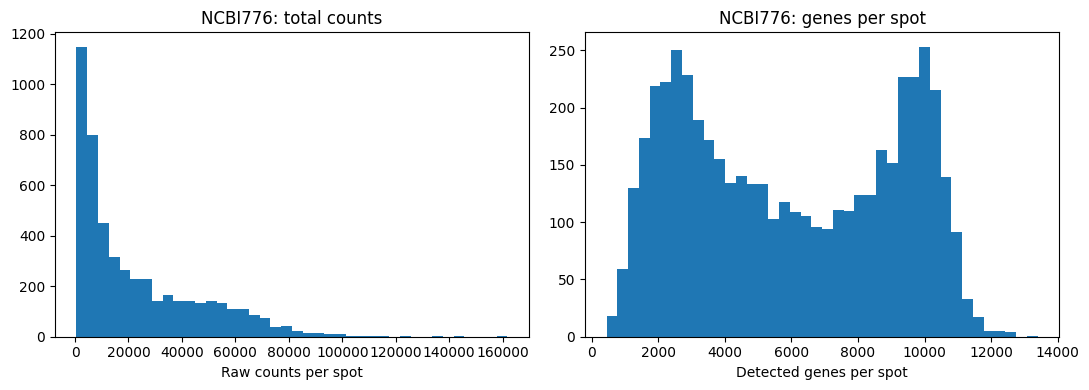

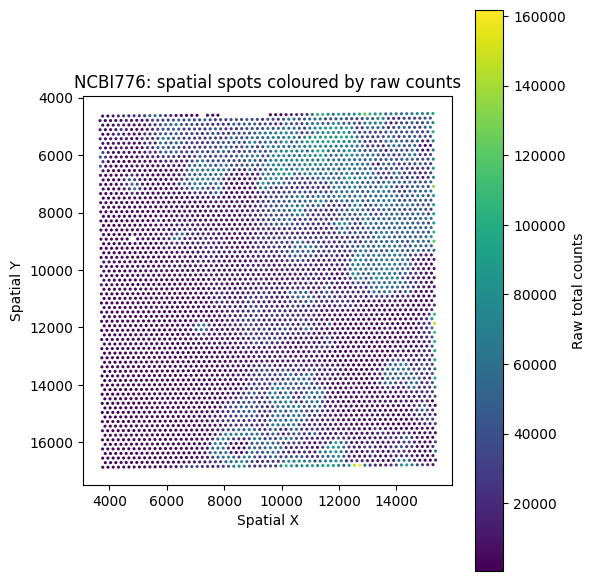

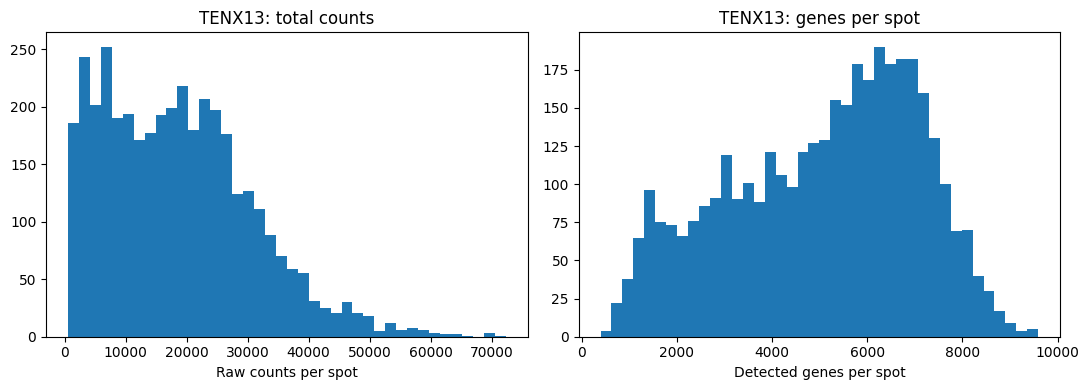

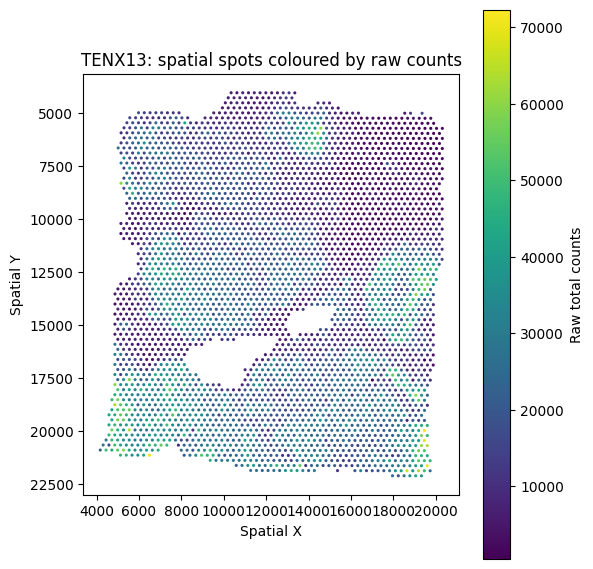

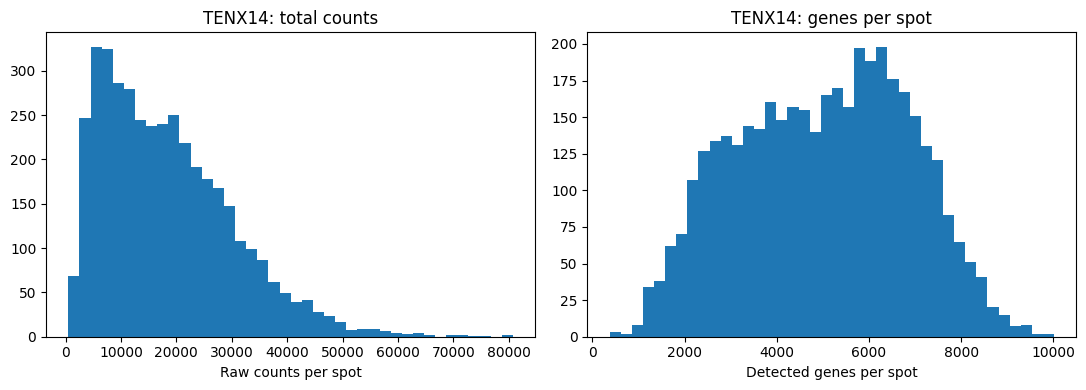

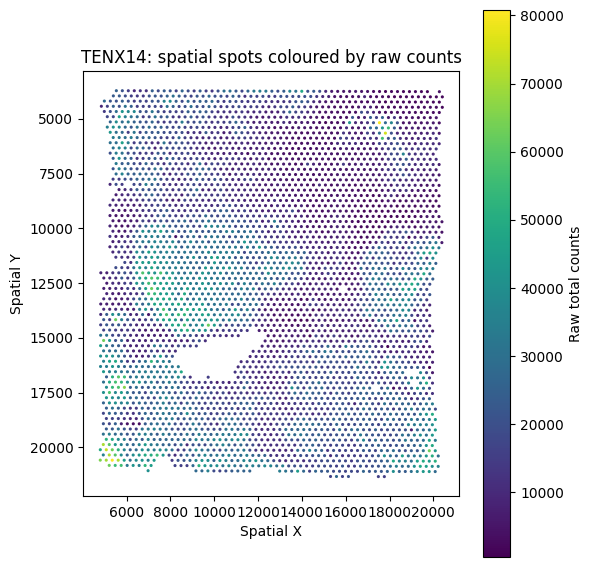

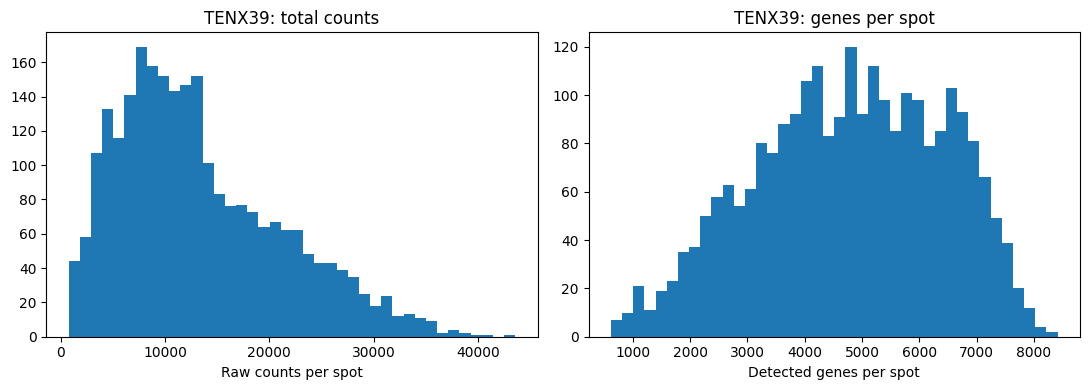

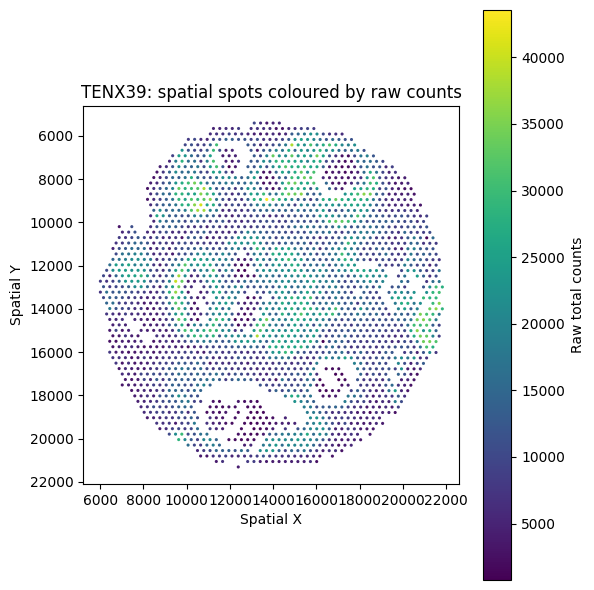

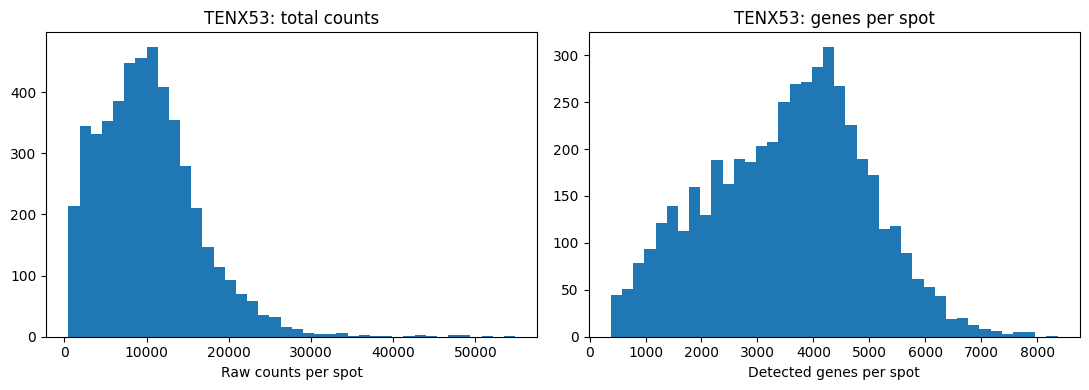

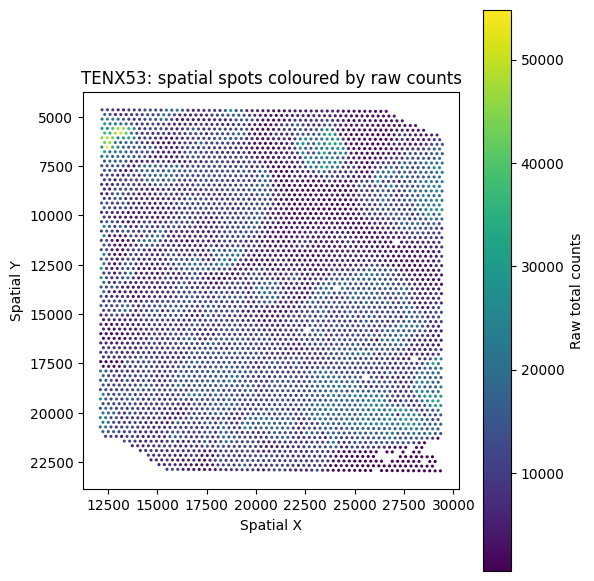

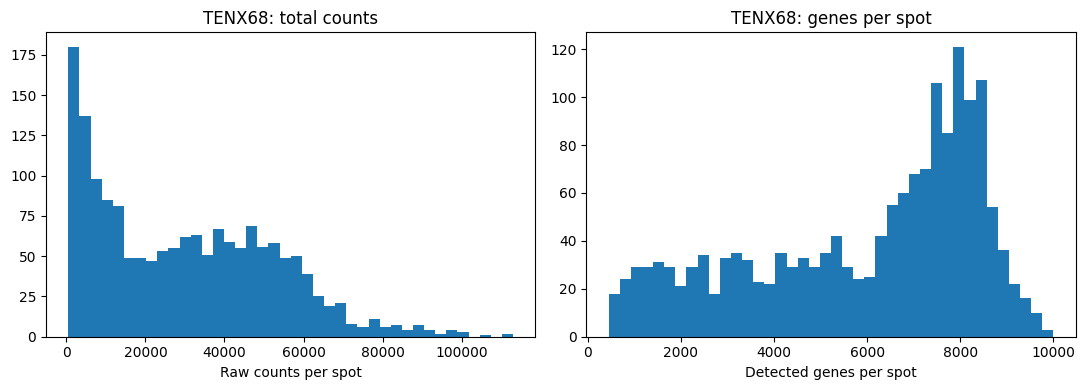

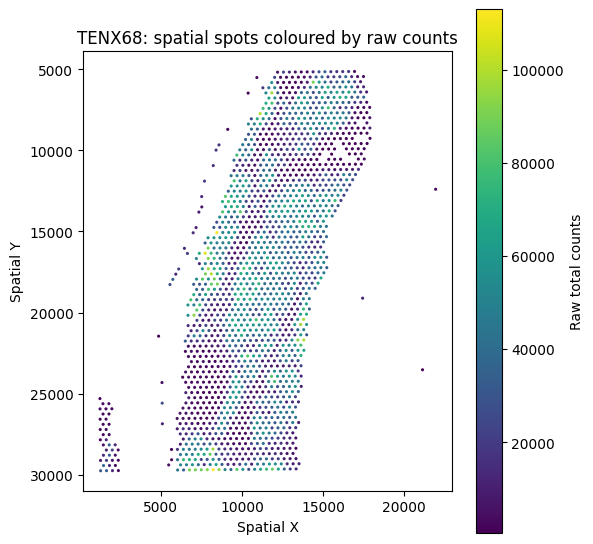

In [13]:
for sid, path in processed_paths.items():
    a = ad.read_h5ad(path)
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].hist(a.obs["total_counts"], bins=40)
    axes[0].set(title=f"{sid}: total counts", xlabel="Raw counts per spot")
    axes[1].hist(a.obs["n_genes_by_counts"], bins=40)
    axes[1].set(title=f"{sid}: genes per spot", xlabel="Detected genes per spot")
    fig.tight_layout()
    fig.savefig(OUT_DIR / f"{sid}_qc_distributions.png", dpi=160)
    plt.show()
    plt.close(fig)

    skey = a.uns["preprocessing"].get("spatial_coordinate_key")
    if skey and skey in a.obsm:
        xy = np.asarray(a.obsm[skey])
        fig, ax = plt.subplots(figsize=(6, 6))
        sca = ax.scatter(xy[:, 0], xy[:, 1], c=a.obs["total_counts"],
                         s=5, cmap="viridis", linewidths=0)
        ax.set(title=f"{sid}: spatial spots coloured by raw counts",
               xlabel="Spatial X", ylabel="Spatial Y")
        ax.invert_yaxis()
        ax.set_aspect("equal", adjustable="box")
        fig.colorbar(sca, ax=ax, label="Raw total counts")
        fig.tight_layout()
        fig.savefig(OUT_DIR / f"{sid}_spatial_qc.png", dpi=180)
        plt.show()
        plt.close(fig)
    else:
        print(sid, ": spatial coordinate matrix not found; plot skipped.")
    del a

## 11. Generate `starter.h5ad` (TENX53)

In [14]:
if STARTER_SAMPLE not in processed_paths:
    if not processed_paths:
        raise RuntimeError("No samples processed successfully.")
    starter_id = next(iter(processed_paths))
    print(f"{STARTER_SAMPLE} not available; using {starter_id}.")
else:
    starter_id = STARTER_SAMPLE

starter = ad.read_h5ad(processed_paths[starter_id])
starter_path = OUT_DIR / "starter.h5ad"
starter.write_h5ad(starter_path, compression="gzip")
print("Created:", starter_path.resolve())
print(starter)

Created: /Users/mayurshadhidhar/Documents/Capstone/datasets/processed/HEST/starter.h5ad
AnnData object with n_obs × n_vars = 4869 × 21349
    obs: 'in_tissue', 'array_row', 'array_col', 'pxl_row_in_fullres', 'pxl_col_in_fullres', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mito', 'log1p_total_counts_mito', 'pct_counts_mito', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'pct_counts_mt', 'sample_id'
    var: 'gene_ids', 'feature_types', 'genome', 'mito', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'original_var_name', 'mt', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'hvg', 'log1p', 'preprocessing', 'sample_id', 'spatial'
    obsm: 'spatial'
    layers: 'counts'


## 12. Validate final starter file

In [15]:
check = ad.read_h5ad(starter_path)
assert check.n_obs > 0 and check.n_vars > 0
assert "counts" in check.layers
assert "highly_variable" in check.var
xvalues = check.X.data if sparse.issparse(check.X) else np.asarray(check.X)
assert np.isfinite(xvalues).all()

skey = check.uns["preprocessing"].get("spatial_coordinate_key")
if skey and skey in check.obsm:
    xy = np.asarray(check.obsm[skey])
    assert xy.shape[0] == check.n_obs and xy.shape[1] >= 2
    assert np.isfinite(xy[:, :2]).all()
    print("Spatial coordinates:", xy.shape)
else:
    print("WARNING: spatial coordinates not detected.")

print("Sample:", check.uns.get("sample_id"))
print("Shape (spots, genes):", check.shape)
print("Raw counts layer:", check.layers["counts"].shape)
print("HVG count:", int(check.var["highly_variable"].sum()))
print("File size MB:", round(starter_path.stat().st_size / 1024**2, 2))
print("STARTER VALIDATION COMPLETE")

Spatial coordinates: (4869, 2)
Sample: TENX53
Shape (spots, genes): (4869, 21349)
Raw counts layer: (4869, 21349)
HVG count: 3000
File size MB: 77.71
STARTER VALIDATION COMPLETE


## Scope

This notebook covers HEST download, source characterization, raw-count validation, spot/gene QC filtering, normalization, log1p transformation, HVG annotation, QC outputs and `starter.h5ad` generation.

In [16]:
print("Output directory:", OUT_DIR.resolve())
for p in sorted(OUT_DIR.iterdir()):
    if p.is_file():
        print(f"{p.name:42s} {p.stat().st_size / 1024**2:8.2f} MB")

Output directory: /Users/mayurshadhidhar/Documents/Capstone/datasets/processed/HEST
NCBI776_processed.h5ad                       129.16 MB
NCBI776_qc_distributions.png                   0.04 MB
NCBI776_qc_metrics.csv                         0.31 MB
NCBI776_qc_summary.json                        0.00 MB
NCBI776_spatial_qc.png                         0.57 MB
TENX13_processed.h5ad                         85.11 MB
TENX13_qc_distributions.png                    0.04 MB
TENX13_qc_metrics.csv                          0.24 MB
TENX13_qc_summary.json                         0.00 MB
TENX13_spatial_qc.png                          0.43 MB
TENX14_processed.h5ad                         88.77 MB
TENX14_qc_distributions.png                    0.04 MB
TENX14_qc_metrics.csv                          0.25 MB
TENX14_qc_summary.json                         0.00 MB
TENX14_spatial_qc.png                          0.46 MB
TENX39_processed.h5ad                         52.72 MB
TENX39_qc_distributions.png         